# Final Ensemble Ablation: FCOS + RetinaNet TTA + RT-DETR-L

**Мета:** визначити, чи покращують FCOS та різні ваги моделей попередній RetinaNet+RT-DETR ensemble. ]


## 1. Kaggle Inputs і параметри


In [ ]:
import os, sys, json, io, gzip, zipfile, shutil, hashlib, contextlib, time, random, math, importlib.util, subprocess, gc
from pathlib import Path
from collections import defaultdict
from dataclasses import dataclass
for module, package in [('pycocotools','pycocotools'), ('ensemble_boxes','ensemble-boxes')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import numpy as np, pandas as pd, torch, torchvision
from PIL import Image
from tqdm.auto import tqdm
from torchvision.ops import batched_nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ensemble_boxes import weighted_boxes_fusion
from IPython.display import display

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
INPUT=Path('/kaggle/input')
WORK=Path('/kaggle/working')
OUT=WORK/'final_ensemble_ablation'
OUT.mkdir(parents=True, exist_ok=True)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| Torch:',torch.__version__, '| TorchVision:',torchvision.__version__)

# Overrides: either path on /kaggle/input, or path to a zip with the file inside.
DATA_ROOT_OVERRIDE=None
PREP_ROOT_OVERRIDE=None
FCOS_SOURCE='/kaggle/input/datasets/nastyadovbenchuk/fcos-result'
RETINA_SOURCE='/kaggle/input/datasets/nastyadovbenchuk/retinanet-results/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt'
RT_SOURCE='/kaggle/input/datasets/nastyadovbenchuk/rt-detr/best.pt'
FCOS_VAL_SOURCE=None
RETINA_TTA_VAL_SOURCE=None
RT_VAL_SOURCE=None

# Choose automatic reuse vs fresh inference
REUSE_EXTERNAL_VAL=True
REUSE_EXISTING_LOCAL=True
FCOS_QUICK_META_REQUIRED=True
RT_EXTERNAL_LABELS='coco_1_8'

# Model inference settings
CONF=0.02
FCOS_SCORE_THRESH=0.02
PER_MODEL_MAX_DET=300
OUTPUT_MAX_DET=500
COCO_MAX_DET=100
RETINA_MIN_SIZE=800
RETINA_MAX_SIZE=1333
RETINA_TTA_NMS_IOU=0.55
RT_IMG_SIZE=640
RT_BATCH=2

# Candidate search
SCREEN_EVERY_N=6
SCREEN_TOP_GLOBAL=8
SCREEN_TOP_PER_FAMILY=1
IOU_GRID=[0.50,0.55]
METHOD_GRID=['nms','wbf']
RUN_TEST=True
TEST_TOP_N=2

CLASSES={1:'person',2:'bicycle',3:'car',4:'van',5:'truck',6:'tricycle',7:'bus',8:'motor'}
MODEL_NAMES=['retina_tta','rtdetr','fcos']

if not INPUT.is_dir():
    print('Not on Kaggle. File discovery will work only when inputs are mounted.')

Device: cuda | Torch: 2.11.0+cu130 | TorchVision: 0.26.0+cu130


## 2. Перевірка вмісту Inputs і точкове розпакування ZIP

In [ ]:
ASSET_NAMES={
    'fcos_weights':['model_weights.pth'],
    'retina_weights':['best_model.pt','retina_best.pt'],
    'rt_weights':['rtdetr_best_for_reuse.pt','rtdetr_trained_best.pt','best.pt'],
    'fcos_val':['val_fcos.json.gz','predictions_quick.json'],
    'retina_val':['val_retina_tta.json.gz'],
    'rt_val':['val_rtdetr_640.json.gz','val_rtdetr.json.gz'],
    'fcos_meta':['metrics_quick.json'],
}
OVERRIDES={'fcos_weights':FCOS_SOURCE,'retina_weights':RETINA_SOURCE,
           'rt_weights':RT_SOURCE,'fcos_val':FCOS_VAL_SOURCE,
           'retina_val':RETINA_TTA_VAL_SOURCE,'rt_val':RT_VAL_SOURCE}

@dataclass
class Asset:
    path: Path
    member: str | None = None
    def describe(self): return f'{self.path}' + (f' :: {self.member}' if self.member else '')

def scan_assets():
    physical=[]; archives=[]
    if not INPUT.is_dir():return physical, archives
    interesting={name for names in ASSET_NAMES.values() for name in names}
    for p in INPUT.rglob('*'):
        if not p.is_file():continue
        if p.name in interesting:physical.append(Asset(p))
        if p.suffix.lower()=='.zip':archives.append(p)
    zipped=[]
    for p in archives:
        try:
            with zipfile.ZipFile(p) as z:
                for info in z.infolist():
                    if not info.is_dir() and Path(info.filename).name in interesting:
                        zipped.append(Asset(p,info.filename))
        except (zipfile.BadZipFile, OSError) as exc: print('Cannot read ZIP:',p,exc)
    return physical+zipped, archives
ALL_ASSETS, ZIP_ARCHIVES=scan_assets()
print('Relevant input files:',len(ALL_ASSETS),'| ZIP archives:',len(ZIP_ARCHIVES))
for a in ALL_ASSETS:
    print(' ',a.describe())

def from_explicit(source, names):
    if not source:return None
    val=str(source)
    if '::' in val:
        left,right=val.split('::',1)
        a=Asset(Path(left.strip()),right.strip())
        assert a.path.exists(),a.describe()
        return a
    p=Path(val)
    assert p.exists(),f'Override missing: {p}'
    if p.is_dir():
        found=[Asset(x) for x in p.rglob('*') if x.is_file() and x.name in names]
        if len(found)!=1: raise ValueError(f'{p}: expected exactly one of {names}, got {found}')
        return found[0]
    if p.suffix.lower()!='.zip':return Asset(p)
    with zipfile.ZipFile(p) as z:
        found=[n for n in z.namelist() if Path(n).name in names]
    if len(found)!=1:raise ValueError(f'ZIP {p}: expected one of {names}, got {found}')
    return Asset(p,found[0])

def choose_asset(kind,required=False):
    names=ASSET_NAMES[kind]
    source=OVERRIDES.get(kind)
    if source:
        asset=from_explicit(source,names)
    else:
        candidates=[a for a in ALL_ASSETS if Path(a.member or a.path.name).name in names]
        # Only VisDrone-trained RT-DETR; exclude unrelated best.pt files.
        if kind=='rt_weights':
            candidates=[a for a in candidates if
                Path(a.member or a.path.name).name!='best.pt' or
                'rtdetr' in a.describe().lower() or 'rtdetr_run' in a.describe().lower()]
        # Prioritize earlier names in ASSET_NAMES.
        if candidates:
            highest=min(names.index(Path(a.member or a.path.name).name) for a in candidates)
            candidates=[a for a in candidates if names.index(Path(a.member or a.path.name).name)==highest]
        if len(candidates)>1:
            print('\nAmbiguous',kind,':',*[a.describe() for a in candidates],sep='\n  ')
            raise ValueError(f'Set explicit {kind} source override in config, then rerun.')
        asset=candidates[0] if candidates else None
    if required and asset is None:raise FileNotFoundError(f'Missing {kind}: add Kaggle Input or set override.')
    return asset

def materialize(asset, target_name=None):
    if asset is None:return None
    if asset.member is None:return asset.path
    base=WORK/'ensemble_selected_inputs'
    base.mkdir(exist_ok=True)
    filename=target_name or Path(asset.member).name
    digest=hashlib.sha1(asset.describe().encode()).hexdigest()[:12]
    out=base/f'{digest}_{filename}'
    if not out.exists():
        with zipfile.ZipFile(asset.path) as z, z.open(asset.member) as src, open(out,'wb') as dst:
            shutil.copyfileobj(src,dst)
    return out

ASSETS={kind:choose_asset(kind) for kind in ASSET_NAMES}
print('\nSELECTED:')
for k,a in ASSETS.items():print(f'{k:16}:',a.describe() if a else 'NOT FOUND (may require inference)')

Relevant input files: 5 | ZIP archives: 0
  /kaggle/input/datasets/nastyadovbenchuk/rt-detr/best.pt
  /kaggle/input/datasets/nastyadovbenchuk/fcos-result/metrics_quick.json
  /kaggle/input/datasets/nastyadovbenchuk/fcos-result/model_weights.pth
  /kaggle/input/datasets/nastyadovbenchuk/fcos-result/predictions_quick.json
  /kaggle/input/datasets/nastyadovbenchuk/retinanet-results/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt

SELECTED:
fcos_weights    : /kaggle/input/datasets/nastyadovbenchuk/fcos-result/model_weights.pth
retina_weights  : /kaggle/input/datasets/nastyadovbenchuk/retinanet-results/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt
rt_weights      : /kaggle/input/datasets/nastyadovbenchuk/rt-detr/best.pt
fcos_val        : /kaggle/input/datasets/nastyadovbenchuk/fcos-result/predictions_quick.json
retina_val      : NOT FOUND (may require inference)
rt_val          : NOT FOUND (may require inference)
fcos_meta       : /kaggle/input/datasets/nastyadovbenchuk/fcos-result/me

## 3. Ground truth: official validation і test metadata


In [3]:
def discover_data_root():
    if DATA_ROOT_OVERRIDE:
        root=Path(DATA_ROOT_OVERRIDE)
        assert (root/'val/annotations_coco.json').is_file()
        return root
    matches=sorted(set(p.parent.parent for p in INPUT.rglob('annotations_coco.json')
                       if p.parent.name=='val' and (p.parent.parent/'train/annotations_coco.json').exists()))
    if len(matches)!=1:raise ValueError(f'Need single DATA_ROOT, got {matches}; set DATA_ROOT_OVERRIDE.')
    return matches[0]

def discover_prep_root():
    if PREP_ROOT_OVERRIDE:
        p=Path(PREP_ROOT_OVERRIDE);assert (p/'val.json').is_file();return p
    matches=sorted(set(p.parent for p in INPUT.rglob('val.json')
                       if (p.parent/'train.json').is_file()))
    if len(matches)!=1:raise ValueError(f'Need single PREP_ROOT, got {matches}; set PREP_ROOT_OVERRIDE.')
    return matches[0]

DATA_ROOT=discover_data_root()
PREP_ROOT=discover_prep_root()
print('DATA_ROOT:', DATA_ROOT)
print('PREP_ROOT:', PREP_ROOT)

def find_image(split, filename):
    rel=Path(str(filename).replace('\\','/').lstrip('/'))
    if '..' in rel.parts:raise ValueError(f'Unsafe path {filename}')
    candidates=[DATA_ROOT/split/rel, DATA_ROOT/split/'images'/rel, DATA_ROOT/rel]
    if rel.parts and rel.parts[0]==split:
        tail=Path(*rel.parts[1:]);candidates += [DATA_ROOT/rel,DATA_ROOT/split/tail]
    for p in candidates:
        if p.is_file():return p
    raise FileNotFoundError(f'Image not found: split={split}, file={filename}')

orig=json.loads((DATA_ROOT/'val/annotations_coco.json').read_text())
orig_byid={int(x['id']):x for x in orig['images']}
prepped=json.loads((PREP_ROOT/'val.json').read_text())
assert len(prepped)==len(orig_byid), f'Validation size differs: {len(prepped)} vs {len(orig_byid)}'
val_records=[]
for r in prepped:
    iid=int(r['image_id']); o=orig_byid[iid]
    boxes=r['boxes'];labels=[int(x) for x in r['labels']]
    assert set(labels).issubset(CLASSES)
    assert len(boxes)==len(labels)
    row={'image_id':iid, 'file_name':r.get('file_name',o['file_name']),
         'width':int(o['width']),'height':int(o['height']),
         'boxes':boxes,'labels':labels,'ignored_boxes':r.get('ignored_boxes',[])}
    val_records.append(row)
assert len(set(r['image_id'] for r in val_records))==len(val_records)
val_records.sort(key=lambda r:(str(r['file_name']).rsplit('/',1)[0],str(r['file_name'])))
for r in (val_records[0],val_records[len(val_records)//2],val_records[-1]):
    assert find_image('val',r['file_name']).is_file()
print('Full validation frames:',len(val_records))

# Optional test metadata is needed only when RUN_TEST=True.
TEST_META_FILE=None
for p in INPUT.rglob('test_images.csv'):
    if TEST_META_FILE is not None and p!=TEST_META_FILE:
        print('Multiple test_images.csv; prefer one under DATA_ROOT')
    if TEST_META_FILE is None or DATA_ROOT in p.parents:TEST_META_FILE=p
print('Test metadata:',TEST_META_FILE)

VAL_IDS=set(r['image_id'] for r in val_records)
val_id_hash=hashlib.sha256(json.dumps(sorted(VAL_IDS)).encode()).hexdigest()
(OUT/'validation_ids.json').write_text(json.dumps({'n':len(VAL_IDS),'sha256':val_id_hash,'ids':sorted(VAL_IDS)}))

DATA_ROOT: /kaggle/input/datasets/nastyadovbenchuk/multiple-object-video-detection
PREP_ROOT: /kaggle/input/datasets/nastyadovbenchuk/preprocessing
Full validation frames: 2846
Test metadata: /kaggle/input/datasets/nastyadovbenchuk/multiple-object-video-detection/test_images.csv


16067

In [ ]:
CACHE_CONTRACT={
    'version':'ensemble-v1',
    'validation_ids_sha256':val_id_hash,
    'validation_count':len(val_records),
    'inputs':{k:(v.describe() if v else None) for k,v in ASSETS.items()},
    'confidence':CONF,'fcos_score_thresh':FCOS_SCORE_THRESH,
    'per_model_max_det':PER_MODEL_MAX_DET,'retina_tta_iou':RETINA_TTA_NMS_IOU,
    'rt_img_size':RT_IMG_SIZE,
    'screen_every_n':SCREEN_EVERY_N,'methods':METHOD_GRID,'iou_grid':IOU_GRID,
    'preds_label_mapping':RT_EXTERNAL_LABELS,
}
contract_path=OUT/'cache_contract.json'
if contract_path.is_file():
    old=json.loads(contract_path.read_text())
    if old!=CACHE_CONTRACT:
        raise RuntimeError('Cached output was created with different inputs/settings. '
            'Change OUT to a new directory or delete old cached files before continuing. '
            f'Previous contract: {contract_path}')
else:
    contract_path.write_text(json.dumps(CACHE_CONTRACT,indent=2,ensure_ascii=False))
print('Cache contract verified: dataset / checkpoint paths / inference settings are fixed.')

Cache contract verified: dataset / checkpoint paths / inference settings are fixed.


In [5]:
def xyxy_to_xywh(box):
    x1,y1,x2,y2=map(float,box)
    return [x1,y1,max(0.,x2-x1),max(0.,y2-y1)]
def xywh_to_xyxy(box):
    x,y,w,h=map(float,box)
    return [x,y,x+w,y+h]

def build_coco_gt(records):
    images=[];annotations=[]
    for r in records:
        iid=int(r['image_id'])
        images.append({'id':iid,'width':int(r['width']),'height':int(r['height']),
                       'file_name':str(r['file_name'])})
        for b,cls in zip(r['boxes'],r['labels']):
            xywh=xyxy_to_xywh(b)
            if xywh[2]<=0 or xywh[3]<=0:continue
            annotations.append({'id':len(annotations)+1,'image_id':iid,'category_id':int(cls),
                 'bbox':xywh,'area':xywh[2]*xywh[3],'iscrowd':0})
        for b in r.get('ignored_boxes',[]):
            xywh=xyxy_to_xywh(b)
            if xywh[2]<=0 or xywh[3]<=0:continue
            for cls in CLASSES:
                annotations.append({'id':len(annotations)+1,'image_id':iid,'category_id':cls,
                    'bbox':xywh,'area':xywh[2]*xywh[3],'iscrowd':1,'ignore':1})
    gt=COCO()
    gt.dataset={'images':images,'annotations':annotations,
                'categories':[{'id':k,'name':v} for k,v in CLASSES.items()],
                'info':{},'licenses':[]}
    with contextlib.redirect_stdout(io.StringIO()):gt.createIndex()
    return gt

COCO_FULL=build_coco_gt(val_records)

def coco_metrics(preds,gt=COCO_FULL):
    target=set(gt.getImgIds())
    for p in preds:
        assert type(p['image_id']) is int, ('COCO image_id must be int',p['image_id'])
        assert p['image_id'] in target, ('Wrong validation image_id',p['image_id'])
        assert p['category_id'] in CLASSES
    with contextlib.redirect_stdout(io.StringIO()):
        if preds:dt=gt.loadRes(preds)
        else:
            dt=COCO();dt.dataset={'images':gt.dataset['images'],'annotations':[],
                'categories':gt.dataset['categories'],'info':{},'licenses':[]};dt.createIndex()
        ev=COCOeval(gt,dt,'bbox')
        ev.params.imgIds=sorted(target)
        ev.params.catIds=list(CLASSES)
        ev.params.maxDets=[1,10,COCO_MAX_DET]
        ev.evaluate();ev.accumulate();ev.summarize()
    return {k:float(ev.stats[i]) for i,k in enumerate(
        ('mAP','AP50','AP75','AP_small','AP_medium','AP_large'))}

def read_json(path):
    with (gzip.open(path,'rt',encoding='utf8') if str(path).endswith('.gz')
          else open(path,'rt',encoding='utf8')) as f:
        return json.load(f)
def write_gz(path,data):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    with gzip.open(path,'wt',encoding='utf8',compresslevel=5) as f:
        json.dump(data,f,separators=(',',':'))

def pred_from_xyxy(iid,boxes,labels,scores):
    result=[]
    for b,label,score in zip(boxes,labels,scores):
        cat=int(label);sc=float(score)
        if cat not in CLASSES or not math.isfinite(sc) or sc<CONF:continue
        box=xyxy_to_xywh(b)
        if box[2]>0 and box[3]>0 and all(math.isfinite(x) for x in box):
            result.append({'image_id':iid if isinstance(iid,str) else int(iid),
                           'category_id':cat,'bbox':box,'score':sc})
    return result

def normalize_preds(items,kind='val',label_mode='coco_1_8'):
    if isinstance(items,dict):
        items=items.get('predictions',None)
    if not isinstance(items,list):raise TypeError('Expected list of COCO prediction dicts')
    result=[]
    for q in items:
        iid=int(q['image_id']) if kind=='val' else str(q['image_id'])
        cls=int(q['category_id']) + (1 if label_mode=='ultralytics_0_7' else 0)
        if cls not in CLASSES:raise ValueError(f'Invalid class={cls}, check label mapping')
        b=list(map(float,q['bbox']));sc=float(q['score'])
        if len(b)!=4 or not all(math.isfinite(x) for x in b+[sc]):raise ValueError('Invalid bbox/score')
        if sc<0 or sc>1:raise ValueError(f'Invalid score {sc}')
        if b[2]>0 and b[3]>0 and sc>=CONF:
            result.append({'image_id':iid,'category_id':cls,'bbox':b,'score':sc})
    if kind=='val' and not set(x['image_id'] for x in result).issubset(VAL_IDS):
        raise ValueError('External validation predictions contain IDs not in official validation!')
    return result

def group_preds(preds):
    result=defaultdict(list)
    for p in preds:result[str(p['image_id'])].append(p)
    return result

print('COCO GT ready:', len(COCO_FULL.getImgIds()), 'images')

COCO GT ready: 2846 images


## 4. Завантаження наявних validation predictions


In [ ]:
def optional_external_predictions(model):
    key={'fcos':'fcos_val','retina_tta':'retina_val','rtdetr':'rt_val'}[model]
    asset=ASSETS.get(key)
    if not REUSE_EXTERNAL_VAL or asset is None:return None
    path=materialize(asset, f'{model}_external_'+Path(asset.member or asset.path.name).name)
    if model=='fcos' and Path(asset.member or asset.path.name).name=='predictions_quick.json':
        meta=ASSETS.get('fcos_meta')
        if not meta:
            print('FCOS quick predictions: no metrics_quick.json; will re-infer full validation.')
            return None
        metrics=read_json(materialize(meta,'fcos_quick_meta.json'))
        n=metrics.get('images_evaluated')
        if n is None:
            print('FCOS quick predictions: no image count; will re-infer full validation.')
            return None
        if int(n)!=len(val_records):
            print('FCOS quick covers',n,'images, not',len(val_records),'; will re-infer.')
            return None
    labels=RT_EXTERNAL_LABELS if model=='rtdetr' else 'coco_1_8'
    records=normalize_preds(read_json(path),'val',labels)
    print(f'Reusing {model} validation predictions:',len(records),asset.describe())
    return records

val_preds={}
for model in MODEL_NAMES:
    savefile=OUT/f'val_{model}.json.gz'
    if REUSE_EXISTING_LOCAL and savefile.exists():
        val_preds[model]=normalize_preds(read_json(savefile),'val')
        print('Local cache',model,len(val_preds[model]))
    else:
        ext=optional_external_predictions(model)
        if ext is not None:
            val_preds[model]=ext
            write_gz(savefile,ext)
print('Existing validation outputs:',list(val_preds))

Reusing fcos validation predictions: 203039 /kaggle/input/datasets/nastyadovbenchuk/fcos-result/predictions_quick.json
Existing validation outputs: ['fcos']


## 5. Inference тільки для відсутніх моделей

*Варто запускати тільки, якщо не має raw predictions для певних моделей*


In [ ]:
def get_checkpoint(kind):
    asset=ASSETS.get(kind)
    if asset is None:
        raise FileNotFoundError(f'{kind} unavailable. Add checkpoint or full validation predictions.')
    path=materialize(asset,f'{kind}_{Path(asset.member or asset.path.name).name}')
    print('Using',kind,':',path)
    return path

def infer_fcos(records,split='val'):
    from torchvision.models.detection import fcos_resnet50_fpn
    from torchvision.models.detection.fcos import FCOSClassificationHead
    ck=get_checkpoint('fcos_weights')
    net=fcos_resnet50_fpn(weights=None,weights_backbone=None,num_classes=9,
        min_size=800,max_size=1333,score_thresh=FCOS_SCORE_THRESH,
        detections_per_img=PER_MODEL_MAX_DET,nms_thresh=0.6)
    anchors=net.anchor_generator.num_anchors_per_location()[0]
    net.head.classification_head=FCOSClassificationHead(net.backbone.out_channels,anchors,9)
    sd=torch.load(ck,map_location='cpu',weights_only=True)
    state=sd.get('model',sd) if isinstance(sd,dict) else sd
    net.load_state_dict(state,strict=True)
    net=net.to(DEVICE).eval()
    outputs=[]
    try:
        for rec in tqdm(records,desc=f'FCOS {split}'):
            with Image.open(find_image(split,rec['file_name'])) as im:
                image=np.asarray(im.convert('RGB')).copy()
            tensor=torch.from_numpy(image).permute(2,0,1).float().div(255).to(DEVICE)
            with torch.inference_mode():raw=net([tensor])[0]
            outputs+=pred_from_xyxy(rec['image_id'],raw['boxes'].cpu().tolist(),
                                     raw['labels'].cpu().tolist(),raw['scores'].cpu().tolist())
    finally:
        del net;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return outputs

def infer_retina_tta(records,split='val'):
    from torchvision.models.detection import retinanet_resnet50_fpn
    from torchvision.models.detection.retinanet import RetinaNetClassificationHead
    ck=get_checkpoint('retina_weights')
    net=retinanet_resnet50_fpn(weights=None,weights_backbone=None,
        min_size=RETINA_MIN_SIZE,max_size=RETINA_MAX_SIZE,
        score_thresh=CONF,detections_per_img=PER_MODEL_MAX_DET)
    anchors=net.anchor_generator.num_anchors_per_location()[0]
    net.head.classification_head=RetinaNetClassificationHead(net.backbone.out_channels,anchors,9)
    checkpoint=torch.load(ck,map_location='cpu',weights_only=True)
    state=checkpoint.get('model',checkpoint) if isinstance(checkpoint,dict) else checkpoint
    net.load_state_dict(state,strict=True)
    net=net.to(DEVICE).eval()
    outputs=[]
    try:
        for rec in tqdm(records,desc=f'RetinaNet TTA {split}'):
            with Image.open(find_image(split,rec['file_name'])) as im:
                image=np.asarray(im.convert('RGB')).copy()
            height,width=image.shape[:2]
            x=torch.from_numpy(image).permute(2,0,1).float().div(255).to(DEVICE)
            with torch.inference_mode():
                original=net([x])[0]
                flipped=net([x.flip(-1)])[0]
            b1=original['boxes'].detach().cpu();s1=original['scores'].detach().cpu();l1=original['labels'].detach().cpu()
            b2=flipped['boxes'].detach().cpu().clone();s2=flipped['scores'].detach().cpu();l2=flipped['labels'].detach().cpu()
            if len(b2):
                left=b2[:,0].clone();right=b2[:,2].clone()
                b2[:,0]=width-right;b2[:,2]=width-left
            boxes=torch.cat((b1,b2));scores=torch.cat((s1,s2));labels=torch.cat((l1,l2))
            if len(boxes):
                keep=batched_nms(boxes,scores,labels,RETINA_TTA_NMS_IOU)[:PER_MODEL_MAX_DET]
                boxes=boxes[keep];scores=scores[keep];labels=labels[keep]
            outputs+=pred_from_xyxy(rec['image_id'],boxes.tolist(),labels.tolist(),scores.tolist())
    finally:
        del net;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return outputs

def infer_rtdetr(records,split='val'):
    if importlib.util.find_spec('ultralytics') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.204'])
    from ultralytics import RTDETR
    ck=get_checkpoint('rt_weights')
    net=RTDETR(str(ck))
    assert len(net.names)==8, f'Expected 8 VisDrone classes in RT-DETR, got {net.names}'
    outputs=[]
    try:
        for i in tqdm(range(0,len(records),RT_BATCH),desc=f'RT-DETR {split}'):
            batch=records[i:i+RT_BATCH]
            images=[str(find_image(split,r['file_name'])) for r in batch]
            res=net.predict(source=images,imgsz=RT_IMG_SIZE,conf=CONF,
                max_det=PER_MODEL_MAX_DET,device=DEVICE,quantize=32,verbose=False)
            assert len(res)==len(batch)
            for r,pr in zip(batch,res):
                if pr.boxes is not None:
                    outputs+=pred_from_xyxy(r['image_id'],pr.boxes.xyxy.cpu().tolist(),
                        (pr.boxes.cls.long()+1).cpu().tolist(),pr.boxes.conf.cpu().tolist())
    finally:
        del net;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return outputs

INFER_FNS={'fcos':infer_fcos,'retina_tta':infer_retina_tta,'rtdetr':infer_rtdetr}
for model in MODEL_NAMES:
    if model not in val_preds:
        if DEVICE!='cuda':print('Warning: inference on CPU can be very slow')
        print('Computing missing full-val predictions:',model)
        val_preds[model]=INFER_FNS[model](val_records)
        write_gz(OUT/f'val_{model}.json.gz',val_preds[model])

print('FULL VALIDATION RAW DETECTIONS:', {k:len(v) for k,v in val_preds.items()})

Computing missing full-val predictions: retina_tta
Using retina_weights : /kaggle/input/datasets/nastyadovbenchuk/retinanet-results/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt


RetinaNet TTA val:   0%|          | 0/2846 [00:00<?, ?it/s]

Computing missing full-val predictions: rtdetr
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Using rt_weights : /kaggle/input/datasets/nastyadovbenchuk/rt-detr/best.pt


RT-DETR val:   0%|          | 0/1423 [00:00<?, ?it/s]

FULL VALIDATION RAW DETECTIONS: {'fcos': 203039, 'retina_tta': 571363, 'rtdetr': 849015}


## 6. Окремі моделі: full official validation

Це контрольні результати для коректної ablation: однакові images, COCO GT, ignored regions, maxDets.

In [8]:
base_metrics={name:coco_metrics(preds) for name,preds in val_preds.items()}
base_df=pd.DataFrame.from_dict(base_metrics,orient='index')
base_df.index.name='candidate';base_df.to_csv(OUT/'single_model_full_metrics.csv')
print(base_df.round(5).to_string())
print('Historical Retina+RT-DETR NMS 70/30 (different RT checkpoint): 0.16908 — reference only')

                mAP     AP50     AP75  AP_small  AP_medium  AP_large
candidate                                                           
fcos        0.13237  0.27154  0.11414   0.06550    0.11913   0.27717
retina_tta  0.16171  0.31746  0.14529   0.06837    0.15206   0.30631
rtdetr      0.14483  0.28506  0.12943   0.09246    0.14304   0.23866
Historical Retina+RT-DETR NMS 70/30 (different RT checkpoint): 0.16908 — reference only


## 7. Параметри fusion та комбінації

Для кожної: ваги моделей, class-aware NMS або WBF, IoU thresholds. NMS використовує відносне масштабування confidence `(weight / mean_weight)` з clipping до 1.0; WBF враховує `weights` під час усереднення boxes/scores, остаточний вибір лише за full COCO mAP.

In [ ]:
from itertools import combinations
PAIR_WEIGHTS=[(0.50,0.50),(0.70,0.30),(0.30,0.70)]
TRIPLE_WEIGHTS=[(1/3,1/3,1/3),(0.50,0.30,0.20),(0.50,0.20,0.30),
                (0.30,0.50,0.20),(0.20,0.30,0.50),(0.20,0.50,0.30)]

candidates=[]
for models in combinations(MODEL_NAMES,2):
    for weights in PAIR_WEIGHTS:
        for method in METHOD_GRID:
            for iou in IOU_GRID:
                candidates.append({'models':list(models),'weights':list(weights),
                                   'method':method,'iou':iou})
for weights in TRIPLE_WEIGHTS:
    for method in METHOD_GRID:
        for iou in IOU_GRID:
            candidates.append({'models':MODEL_NAMES.copy(),'weights':list(weights),
                               'method':method,'iou':iou})

def candidate_name(spec):
    names='-'.join(spec['models'])
    ws='-'.join(f'{round(100*x):02d}' for x in spec['weights'])
    return f"{names}__{spec['method']}__w{ws}__iou{int(round(spec['iou']*100)):02d}"
for c in candidates:c['candidate']=candidate_name(c)
assert len(set(c['candidate'] for c in candidates))==len(candidates)
print('Fusion candidates:',len(candidates))
display(pd.DataFrame(candidates)[['candidate','method','iou']].head(12))

Fusion candidates: 60


,candidate,method,iou
0,retina_tta-rtdetr__nms__w50-50__iou50,nms,0.50
1,retina_tta-rtdetr__nms__w50-50__iou55,nms,0.55
2,retina_tta-rtdetr__wbf__w50-50__iou50,wbf,0.50
3,retina_tta-rtdetr__wbf__w50-50__iou55,wbf,0.55
4,retina_tta-rtdetr__nms__w70-30__iou50,nms,0.50
5,retina_tta-rtdetr__nms__w70-30__iou55,nms,0.55
6,retina_tta-rtdetr__wbf__w70-30__iou50,wbf,0.50
7,retina_tta-rtdetr__wbf__w70-30__iou55,wbf,0.55
8,retina_tta-rtdetr__nms__w30-70__iou50,nms,0.50
9,retina_tta-rtdetr__nms__w30-70__iou55,nms,0.55


In [ ]:
GROUPED={name:group_preds(val_preds[name]) for name in MODEL_NAMES}

def fuse_one_record(rec,spec,grouped):
    iid=rec['image_id'];key=str(iid)
    width=float(rec['width']);height=float(rec['height'])
    models=spec['models'];weights=np.asarray(spec['weights'],dtype=float)
    assert len(models)==len(weights) and np.all(weights>0)
    parts=[]
    for model in models:
        rows=grouped[model].get(key,[])
        rows=sorted(rows,key=lambda x:x['score'],reverse=True)[:PER_MODEL_MAX_DET]
        parts.append(rows)
    if not any(parts):return []
    if spec['method']=='nms':
        boxes=[];scores=[];labels=[]
        scale=weights/(weights.mean())
        for j,part in enumerate(parts):
            for r in part:
                x1,y1,x2,y2=xywh_to_xyxy(r['bbox'])
                x1=max(0.,min(width,x1));x2=max(0.,min(width,x2))
                y1=max(0.,min(height,y1));y2=max(0.,min(height,y2))
                if x2<=x1 or y2<=y1:continue
                boxes.append([x1,y1,x2,y2]);labels.append(int(r['category_id']))
                scores.append(min(1.,float(r['score'])*float(scale[j])))
        if not boxes:return []
        boxes=torch.as_tensor(boxes,dtype=torch.float32)
        scores=torch.as_tensor(scores,dtype=torch.float32)
        labels=torch.as_tensor(labels,dtype=torch.int64)
        keep=batched_nms(boxes,scores,labels,float(spec['iou']))[:OUTPUT_MAX_DET]
        return pred_from_xyxy(iid,boxes[keep].tolist(),labels[keep].tolist(),scores[keep].tolist())
    if spec['method']=='wbf':
        boxes_list=[];scores_list=[];labels_list=[]
        for part in parts:
            bl=[];sl=[];ll=[]
            for r in part:
                x1,y1,x2,y2=xywh_to_xyxy(r['bbox'])
                b=[min(1.,max(0.,x1/width)),min(1.,max(0.,y1/height)),
                   min(1.,max(0.,x2/width)),min(1.,max(0.,y2/height))]
                if b[2]<=b[0] or b[3]<=b[1]:continue
                bl.append(b);sl.append(float(r['score']));ll.append(int(r['category_id']))
            boxes_list.append(bl);scores_list.append(sl);labels_list.append(ll)
        if not any(scores_list):return []
        fb,fs,fl=weighted_boxes_fusion(boxes_list,scores_list,labels_list,
             weights=weights.tolist(),iou_thr=float(spec['iou']),
             skip_box_thr=CONF,conf_type='avg')
        order=np.argsort(-np.asarray(fs))[:OUTPUT_MAX_DET]
        boxes=[[float(fb[k][0])*width,float(fb[k][1])*height,
                float(fb[k][2])*width,float(fb[k][3])*height] for k in order]
        return pred_from_xyxy(iid,boxes,[int(fl[k]) for k in order],
                              [float(fs[k]) for k in order])
    raise ValueError(spec['method'])

def fuse_records(records,spec,grouped=GROUPED,progress=False):
    iterator=tqdm(records,desc=spec['candidate'],leave=False) if progress else records
    result=[]
    for r in iterator:result.extend(fuse_one_record(r,spec,grouped))
    return result

# Mini smoke test
probe=val_records[0]
for method in ('nms','wbf'):
    smoke={'candidate':'smoke','models':['retina_tta','rtdetr'],
           'weights':[0.7,0.3],'method':method,'iou':0.55}
    test=fuse_one_record(probe,smoke,GROUPED)
    assert all(type(z['image_id']) is int and z['category_id'] in CLASSES for z in test)
print('Fusion smoke test passed.')

Fusion smoke test passed.


## 8. Screening

*Для економії CPU на першому етапі оцінюємо кожну конфігурацію на приблизно коженому шостому кадрі кожної відеопослідовності. Потім оцінюються на всіх 2 846 кадрах*

In [ ]:
def sequence_key(r):
    return str(r['file_name']).rsplit('/',1)[0]
by_sequence=defaultdict(list)
for r in val_records:by_sequence[sequence_key(r)].append(r)
screen_records=[]
for seq,rows in sorted(by_sequence.items()):
    screen_records+=rows[::SCREEN_EVERY_N]
screen_records.sort(key=lambda r:r['image_id'])
COCO_SCREEN=build_coco_gt(screen_records)
(OUT/'screening_ids.json').write_text(json.dumps([r['image_id'] for r in screen_records]))
print('Screening:',len(screen_records),'frames from',len(by_sequence),'sequences; full:',len(val_records))

screen_results=[]
cache_csv=OUT/'screen_comparison.csv'
if cache_csv.exists():
    old=pd.read_csv(cache_csv)
    if set(old['candidate'])==set(c['candidate'] for c in candidates):
        screen_results=old.to_dict('records')
        print('Restored complete screening cache:',len(screen_results))
if not screen_results:
    for spec in tqdm(candidates,desc='Screening fusion candidates'):
        preds=fuse_records(screen_records,spec)
        metrics=coco_metrics(preds,COCO_SCREEN)
        screen_results.append({'candidate':spec['candidate'],'family':'+'.join(spec['models']),
                               'method':spec['method'],'iou':spec['iou'],
                               'weights':json.dumps(spec['weights']), **metrics})
        # Save partial results after every run for interruption resilience.
        pd.DataFrame(screen_results).to_csv(cache_csv,index=False)
screen_df=pd.DataFrame(screen_results).sort_values('mAP',ascending=False)
print('TOP SCREENING (not final official mAP):')
display(screen_df[['candidate','mAP','AP50','AP_small']].head(15))

Screening: 477 frames from 7 sequences; full: 2846


Screening fusion candidates:   0%|          | 0/60 [00:00<?, ?it/s]

TOP SCREENING (not final official mAP):


,candidate,mAP,AP50,AP_small
37,retina_tta-rtdetr-fcos__nms__w33-33-33__iou55,0.181101,0.363541,0.094856
43,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou55,0.180483,0.363563,0.102614
36,retina_tta-rtdetr-fcos__nms__w33-33-33__iou50,0.180451,0.363030,0.094570
39,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55,0.180235,0.365138,0.103093
42,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou50,0.178058,0.361114,0.101189
38,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou50,0.177912,0.362427,0.100397
1,retina_tta-rtdetr__nms__w50-50__iou55,0.177252,0.354796,0.099356
0,retina_tta-rtdetr__nms__w50-50__iou50,0.176897,0.354528,0.099217
51,retina_tta-rtdetr-fcos__wbf__w30-50-20__iou55,0.176644,0.357393,0.106039
19,retina_tta-fcos__wbf__w70-30__iou55,0.176280,0.345024,0.086827


## 9. Full official COCO evaluation найкращих кандидатів

До повного оцінювання потрапляють 8 найкращих із screening + найкраща конфігурація кожної сім'ї ансамблів (окремі моделі також включені). 

Найкраща комбінація обирається за `mAP` (IoU 0.50–0.95), при рівності — AP_small.

In [ ]:
SPECS={c['candidate']:c for c in candidates}
selected=list(screen_df.head(SCREEN_TOP_GLOBAL)['candidate'])
for family,frame in screen_df.groupby('family'):
    selected+=frame.head(SCREEN_TOP_PER_FAMILY)['candidate'].tolist()
selected=list(dict.fromkeys(selected))
# the historical RetinaNet TTA + RT-DETR NMS 70/30 protocol
historical_baseline=next((name for name,spec in SPECS.items()
    if spec['models']==['retina_tta','rtdetr']
       and spec['method']=='nms' and abs(spec['iou']-0.55)<1e-9
       and spec['weights']==[0.7,0.3]),None)
if historical_baseline and historical_baseline not in selected:
    selected.append(historical_baseline)
print('Full fusion finalists:',len(selected))

full_results=[]
for name,metric in base_metrics.items():
    full_results.append({'candidate':name,'family':'single','method':'single',
        'iou':np.nan,'weights':'[1.0]',**metric})

for name in tqdm(selected,desc='Full evaluation finalists'):
    spec=SPECS[name]
    pred_file=OUT/f'val_ensemble_{name}.json.gz'
    preds=normalize_preds(read_json(pred_file),'val') if pred_file.exists() else fuse_records(val_records,spec)
    if not pred_file.exists():write_gz(pred_file,preds)
    met=coco_metrics(preds)
    full_results.append({'candidate':name,'family':'+'.join(spec['models']),
        'method':spec['method'],'iou':spec['iou'],'weights':json.dumps(spec['weights']),**met})
    # checkpoint full comparison on each candidate
    pd.DataFrame(full_results).sort_values('mAP',ascending=False).to_csv(
        OUT/'full_comparison.csv',index=False)

full_df=pd.DataFrame(full_results).sort_values(['mAP','AP_small'],ascending=False).reset_index(drop=True)
full_df.to_csv(OUT/'full_comparison.csv',index=False)
print('FINAL FULL OFFICIAL VALIDATION:')
display(full_df[['candidate','family','mAP','AP50','AP_small','AP_medium','AP_large']])

# Contribution of each family, measured relative to individual models.
single_best=max(base_metrics,key=lambda k:base_metrics[k]['mAP'])
contribution=[]
for _,r in full_df.iterrows():
    if r['family']=='single':continue
    models=r['family'].split('+')
    strongest=max(base_metrics[m]['mAP'] for m in models)
    contribution.append({'candidate':r['candidate'],'family':r['family'],
                         'delta_vs_best_component':r['mAP']-strongest,
                         'delta_vs_best_single':r['mAP']-base_metrics[single_best]['mAP']})
pd.DataFrame(contribution).to_csv(OUT/'model_contributions.csv',index=False)

triple_rows=full_df[full_df['family'].str.count(r'\+')==2]
loo_results=[]
if not triple_rows.empty:
    top_triple=str(triple_rows.iloc[0]['candidate'])
    three_spec=SPECS[top_triple]
    triple_map=float(triple_rows.iloc[0]['mAP'])
    for dropped in three_spec['models']:
        kept=[m for m in three_spec['models'] if m!=dropped]
        raw_weights=[w for m,w in zip(three_spec['models'],three_spec['weights']) if m!=dropped]
        weight_sum=sum(raw_weights)
        pair_spec={'candidate':f'leave_out_{dropped}', 'models':kept,
            'weights':[w/weight_sum for w in raw_weights],
            'method':three_spec['method'],'iou':three_spec['iou']}
        pair_pred=fuse_records(val_records,pair_spec)
        pair_metric=coco_metrics(pair_pred)
        loo_results.append({'triple_candidate':top_triple,'removed_model':dropped,
            'remaining_models':'+'.join(kept),'triple_mAP':triple_map,
            'without_mAP':pair_metric['mAP'],
            'marginal_contribution_mAP':triple_map-pair_metric['mAP'],
            'without_AP_small':pair_metric['AP_small']})
    pd.DataFrame(loo_results).to_csv(OUT/'leave_one_out.csv',index=False)
    print('LEAVE-ONE-OUT contributions of best triple:')
    display(pd.DataFrame(loo_results)[['removed_model','triple_mAP','without_mAP',
                                       'marginal_contribution_mAP']])
else:
    print('No triple finalist was evaluated; leave-one-out skipped.')

winner=str(full_df.iloc[0]['candidate'])
selection={'winner':winner,'runner_up':str(full_df.iloc[1]['candidate']),
           'ranking_metric':'full official validation COCO mAP','n_val_frames':len(val_records),
           'single_results':base_metrics,'winner_spec':SPECS.get(winner),
           'runner_up_spec':SPECS.get(str(full_df.iloc[1]['candidate'])),
           'historical_mAP_reference':0.16908,'screening_only_for_shortlisting':True,
           'checkpoint_asset_sources':{k:(v.describe() if v else None) for k,v in ASSETS.items()}}
(OUT/'ensemble_selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
print('BEST:',winner,'mAP',round(float(full_df.iloc[0]['mAP']),5))
print('RUN_TEST is',RUN_TEST,'— inspect the table before generating test predictions.')

Full fusion finalists: 11


Full evaluation finalists:   0%|          | 0/11 [00:00<?, ?it/s]

FINAL FULL OFFICIAL VALIDATION:


,candidate,family,mAP,AP50,AP_small,AP_medium,AP_large
0,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55,retina_tta+rtdetr+fcos,0.179263,0.363204,0.101176,0.170821,0.330724
1,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou55,retina_tta+rtdetr+fcos,0.179168,0.360807,0.099838,0.169142,0.329431
2,retina_tta-rtdetr-fcos__nms__w33-33-33__iou55,retina_tta+rtdetr+fcos,0.178493,0.360691,0.092211,0.170562,0.312437
3,retina_tta-rtdetr-fcos__nms__w33-33-33__iou50,retina_tta+rtdetr+fcos,0.178051,0.360658,0.091784,0.170205,0.311073
4,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou50,retina_tta+rtdetr+fcos,0.177242,0.361063,0.099356,0.168973,0.326553
5,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou50,retina_tta+rtdetr+fcos,0.176635,0.358091,0.097750,0.166687,0.325483
6,retina_tta-rtdetr__nms__w50-50__iou55,retina_tta+rtdetr,0.175026,0.351898,0.094519,0.167822,0.302841
7,retina_tta-rtdetr__nms__w50-50__iou50,retina_tta+rtdetr,0.174869,0.352141,0.094187,0.167577,0.302333
8,retina_tta-fcos__wbf__w70-30__iou55,retina_tta+fcos,0.172683,0.339818,0.084190,0.160283,0.329447
9,rtdetr-fcos__nms__w50-50__iou55,rtdetr+fcos,0.162833,0.333167,0.086733,0.158231,0.282798


LEAVE-ONE-OUT contributions of best triple:


,removed_model,triple_mAP,without_mAP,marginal_contribution_mAP
0,retina_tta,0.179263,0.156533,0.022730
1,rtdetr,0.179263,0.172085,0.007179
2,fcos,0.179263,0.170279,0.008984


BEST: retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55 mAP 0.17926
RUN_TEST is False — inspect the table before generating test predictions.


## 10. Додаткова оцінка більшої кількості різних комбінацій моделей

*В основному увага зверталась на вагу саме FCOS*

In [ ]:
import json, hashlib
from pathlib import Path

needed = ['GROUPED', 'SPECS', 'candidates', 'full_df', 'val_records', 'screen_records',
          'COCO_SCREEN', 'coco_metrics', 'candidate_name', 'fuse_records',
          'base_metrics', 'selection', 'OUT', 'METHOD_GRID', 'IOU_GRID']
missing = [key for key in needed if key not in globals()]
assert not missing, f"Run previous notebook cells first. Missing: {missing}"

# Weights are in model order. Existing candidates are not reevaluated.
HEAVY_PAIR_WEIGHTS = [
    (0.40, 0.60), (0.30, 0.70), (0.20, 0.80), (0.10, 0.90)
]
# Triple order: RetinaNet TTA, RT-DETR, FCOS.
HEAVY_TRIPLE_WEIGHTS = [
    (0.40, 0.20, 0.40), (0.30, 0.30, 0.40), (0.20, 0.40, 0.40),
    (0.40, 0.10, 0.50), (0.30, 0.20, 0.50), (0.20, 0.30, 0.50),
    (0.10, 0.40, 0.50), (0.30, 0.10, 0.60), (0.20, 0.20, 0.60),
    (0.10, 0.30, 0.60), (0.20, 0.10, 0.70), (0.10, 0.20, 0.70),
    (0.10, 0.10, 0.80),
]

HEAVY_TOP_FULL_GLOBAL = 8
HEAVY_TOP_PER_FAMILY_METHOD = 1
HEAVY_INCLUDE_BEST_AP_SMALL = True

original_candidate_names = {sp['candidate'] for sp in candidates}
heavy_specs = []
for models in [('retina_tta', 'fcos'), ('rtdetr', 'fcos')]:
    for weights in HEAVY_PAIR_WEIGHTS:
        for method in METHOD_GRID:
            for iou in IOU_GRID:
                sp = {'models': list(models), 'weights': list(weights),
                      'method': method, 'iou': float(iou)}
                sp['candidate'] = candidate_name(sp)
                if sp['candidate'] not in original_candidate_names:
                    heavy_specs.append(sp)
for weights in HEAVY_TRIPLE_WEIGHTS:
    assert abs(sum(weights)-1) < 1e-8
    for method in METHOD_GRID:
        for iou in IOU_GRID:
            sp = {'models': ['retina_tta', 'rtdetr', 'fcos'],
                  'weights': list(weights), 'method': method, 'iou': float(iou)}
            sp['candidate'] = candidate_name(sp)
            if sp['candidate'] not in original_candidate_names:
                heavy_specs.append(sp)

heavy_by_name = {sp['candidate']: sp for sp in heavy_specs}
assert len(heavy_by_name) == len(heavy_specs), 'Duplicate candidate names'
assert all(abs(sum(sp['weights']) - 1.0) < 1e-6 for sp in heavy_specs)
SPECS.update(heavy_by_name)    # IMPORTANT for later test inference
print(f'New FCOS-heavy candidates: {len(heavy_specs)}')
print('Models and weights refer to fusion, not training.')

heavy_contract = {
    'base_cache_contract': CACHE_CONTRACT,
    'screen_image_ids_sha': hashlib.sha256(
        json.dumps([r['image_id'] for r in screen_records]).encode()
    ).hexdigest(),
    'new_specifications': heavy_specs,
    'full_validation_count': len(val_records),
}
heavy_contract_file = OUT / 'fcos_heavy_cache_contract.json'
if heavy_contract_file.exists():
    previous = json.loads(heavy_contract_file.read_text())
    assert previous == heavy_contract, (
        'FCOS-heavy cache belongs to different data/settings. '
        'Rename the output directory or remove FCOS-heavy cache files first.'
    )
else:
    heavy_contract_file.write_text(json.dumps(heavy_contract, indent=2))

# ------------------------------------------------------------
# Stage A. SCREENING — use the SAME screen_records/COCO_SCREEN.
# ------------------------------------------------------------
screen_path = OUT / 'fcos_heavy_screen_comparison.csv'
screen_rows = []
if screen_path.exists():
    old = pd.read_csv(screen_path)
    assert set(old['candidate']).issubset(heavy_by_name), 'Unexpected candidate in heavy screen cache'
    screen_rows = old.drop_duplicates('candidate').to_dict('records')
processed = {r['candidate'] for r in screen_rows}

for sp in tqdm(heavy_specs, desc='FCOS-heavy screening'):
    if sp['candidate'] in processed:
        continue
    pred = fuse_records(screen_records, sp, GROUPED)
    met = coco_metrics(pred, COCO_SCREEN)
    screen_rows.append({
        'candidate': sp['candidate'],
        'family': '+'.join(sp['models']),
        'method': sp['method'],
        'iou': sp['iou'],
        'weights': json.dumps(sp['weights']),
        'fcos_weight': sp['weights'][sp['models'].index('fcos')],
        **met,
    })
    processed.add(sp['candidate'])
    pd.DataFrame(screen_rows).to_csv(screen_path, index=False)

heavy_screen_df = pd.DataFrame(screen_rows).sort_values(
    ['mAP', 'AP_small'], ascending=False
).reset_index(drop=True)
print('\nTOP FCOS-HEAVY SCREENING (477 frames; NOT full mAP):')
display(heavy_screen_df[['candidate', 'fcos_weight', 'mAP', 'AP50', 'AP_small']].head(15))

# ------------------------------------------------------------
# Stage B. FULL COCO validation for promising new candidates.
# ------------------------------------------------------------
to_evaluate = heavy_screen_df.head(HEAVY_TOP_FULL_GLOBAL)['candidate'].tolist()
for _, frame in heavy_screen_df.groupby(['family', 'method']):
    to_evaluate += frame.head(HEAVY_TOP_PER_FAMILY_METHOD)['candidate'].tolist()
if HEAVY_INCLUDE_BEST_AP_SMALL:
    to_evaluate += heavy_screen_df.sort_values('AP_small', ascending=False).head(1)['candidate'].tolist()
to_evaluate = list(dict.fromkeys(to_evaluate))
print(f'FCOS-heavy finalists on all {len(val_records)} frames: {len(to_evaluate)}')

full_heavy_path = OUT / 'fcos_heavy_full_comparison.csv'
heavy_full_rows = []
if full_heavy_path.exists():
    old = pd.read_csv(full_heavy_path)
    assert set(old['candidate']).issubset(heavy_by_name), 'Unexpected candidate in heavy full cache'
    heavy_full_rows = old.drop_duplicates('candidate').to_dict('records')
done = {r['candidate'] for r in heavy_full_rows}
for name in tqdm(to_evaluate, desc='FCOS-heavy FULL validation'):
    if name in done:
        continue
    sp = heavy_by_name[name]
    pred = fuse_records(val_records, sp, GROUPED)
    met = coco_metrics(pred)
    heavy_full_rows.append({
        'candidate': name,
        'family': '+'.join(sp['models']),
        'method': sp['method'],
        'iou': sp['iou'],
        'weights': json.dumps(sp['weights']),
        'fcos_weight': sp['weights'][sp['models'].index('fcos')],
        **met,
    })
    done.add(name)
    pd.DataFrame(heavy_full_rows).to_csv(full_heavy_path, index=False)

heavy_full_df = pd.DataFrame(heavy_full_rows).sort_values(
    ['mAP', 'AP_small'], ascending=False
).reset_index(drop=True)
print('\nFCOS-HEAVY FULL VALIDATION:')
display(heavy_full_df[['candidate', 'fcos_weight', 'mAP', 'AP50', 'AP_small']].head(15))

# ------------------------------------------------------------
# Stage C. Merge into original leaderboard; keep original
# candidates and all prior results, WITHOUT duplicated rows.
# ------------------------------------------------------------
full_df = pd.concat([full_df, heavy_full_df], ignore_index=True)
full_df = (full_df.drop_duplicates('candidate', keep='last')
           .sort_values(['mAP', 'AP_small'], ascending=False)
           .reset_index(drop=True))
full_df.to_csv(OUT / 'full_comparison.csv', index=False)
print('\nCOMBINED FULL OFFICIAL VALIDATION (old + FCOS-heavy):')
display(full_df[['candidate', 'mAP', 'AP50', 'AP_small', 'AP_medium', 'AP_large']].head(18))

# ------------------------------------------------------------
# Stage D. Update winner and downstream test/submission selection.
# ------------------------------------------------------------
old_winner = selection['winner']
winner = str(full_df.iloc[0]['candidate'])
runner_up = str(full_df.iloc[1]['candidate'])
selection.update({
    'winner': winner,
    'runner_up': runner_up,
    'winner_spec': SPECS.get(winner),
    'runner_up_spec': SPECS.get(runner_up),
    'ranking_metric': 'full official validation COCO mAP',
    'extended_with_fcos_heavy': True,
    'fcos_heavy_evaluated_full': len(heavy_full_rows),
    'fcos_heavy_screened': len(heavy_specs),
})
(OUT / 'ensemble_selection.json').write_text(json.dumps(selection, indent=2, ensure_ascii=False))

# Refresh contribution metrics for all combined candidates.
single_best = max(base_metrics, key=lambda k: base_metrics[k]['mAP'])
contribution = []
for _, row in full_df.iterrows():
    if row['family'] == 'single':
        continue
    models = row['family'].split('+')
    strongest = max(base_metrics[m]['mAP'] for m in models)
    contribution.append({
        'candidate': row['candidate'],
        'family': row['family'],
        'delta_vs_best_component': float(row['mAP'])-strongest,
        'delta_vs_best_single': float(row['mAP'])-base_metrics[single_best]['mAP'],
    })
pd.DataFrame(contribution).to_csv(OUT/'model_contributions.csv', index=False)

# Refresh leave-one-out metrics if the best triple has changed.
triple_rows = full_df[full_df['family'].str.count(r'\+') == 2]
if not triple_rows.empty:
    top_triple = str(triple_rows.iloc[0]['candidate'])
    sp = SPECS[top_triple]
    triple_map = float(triple_rows.iloc[0]['mAP'])
    loo_rows = []
    for removed in sp['models']:
        kept = [m for m in sp['models'] if m != removed]
        w = [v for m,v in zip(sp['models'], sp['weights']) if m != removed]
        pair_sp = {
            'candidate': f'fcos_heavy_loo_without_{removed}',
            'models': kept,
            'weights': [v / sum(w) for v in w],
            'method': sp['method'],
            'iou': sp['iou'],
        }
        met = coco_metrics(fuse_records(val_records, pair_sp, GROUPED))
        loo_rows.append({
            'triple_candidate': top_triple,
            'removed_model': removed,
            'remaining_models': '+'.join(kept),
            'triple_mAP': triple_map,
            'without_mAP': met['mAP'],
            'marginal_contribution_mAP': triple_map - met['mAP'],
            'without_AP_small': met['AP_small'],
        })
    pd.DataFrame(loo_rows).to_csv(OUT/'leave_one_out.csv',index=False)
    print('\nLEAVE-ONE-OUT FOR BEST TRIPLE:')
    display(pd.DataFrame(loo_rows)[['removed_model','without_mAP','marginal_contribution_mAP']])

# Keep merged predictions for the overall top two candidates only.
for rank, name in enumerate(full_df.head(2)['candidate'], 1):
    path = OUT / f'val_top_{rank}_after_fcos_heavy.json.gz'
    if name in base_metrics:
        pred = val_preds[name]
    else:
        pred = fuse_records(val_records, SPECS[name], GROUPED)
    write_gz(path, pred)

print('\nPREVIOUS WINNER:', old_winner)
print('UPDATED WINNER: ', winner, 'mAP=', round(float(full_df.iloc[0]['mAP']), 6))
print('RUN_TEST:', RUN_TEST, '(keep False until you are ready to generate submission)')
print('Saved: full_comparison.csv, fcos_heavy_*.csv, ensemble_selection.json')


New FCOS-heavy candidates: 72
Models and weights refer to fusion, not training.


FCOS-heavy screening:   0%|          | 0/72 [00:00<?, ?it/s]


TOP FCOS-HEAVY SCREENING (477 frames; NOT full mAP):


,candidate,fcos_weight,mAP,AP50,AP_small
0,retina_tta-rtdetr-fcos__wbf__w30-30-40__iou55,0.4,0.177307,0.360401,0.101344
1,retina_tta-rtdetr-fcos__wbf__w20-40-40__iou55,0.4,0.175248,0.355408,0.101166
2,retina_tta-rtdetr-fcos__wbf__w30-30-40__iou50,0.4,0.174520,0.356745,0.098940
3,retina_tta-rtdetr-fcos__wbf__w20-40-40__iou50,0.4,0.172827,0.351963,0.098820
4,retina_tta-rtdetr-fcos__wbf__w40-20-40__iou55,0.4,0.172573,0.352836,0.097942
5,retina_tta-fcos__wbf__w40-60__iou55,0.6,0.171615,0.338975,0.086739
6,retina_tta-rtdetr-fcos__wbf__w40-20-40__iou50,0.4,0.169915,0.349356,0.095316
7,retina_tta-rtdetr-fcos__nms__w20-40-40__iou55,0.4,0.168997,0.347532,0.091295
8,retina_tta-fcos__wbf__w40-60__iou50,0.6,0.168405,0.334642,0.085113
9,retina_tta-rtdetr-fcos__nms__w20-40-40__iou50,0.4,0.168354,0.347143,0.090932


FCOS-heavy finalists on all 2846 frames: 11


FCOS-heavy FULL validation:   0%|          | 0/11 [00:00<?, ?it/s]

... (3 outputs left out)

,candidate,mAP,AP50,AP_small,AP_medium,AP_large
0,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55,0.179263,0.363204,0.101176,0.170821,0.330724
1,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou55,0.179168,0.360807,0.099838,0.169142,0.329431
2,retina_tta-rtdetr-fcos__nms__w33-33-33__iou55,0.178493,0.360691,0.092211,0.170562,0.312437
3,retina_tta-rtdetr-fcos__nms__w33-33-33__iou50,0.178051,0.360658,0.091784,0.170205,0.311073
4,retina_tta-rtdetr-fcos__wbf__w33-33-33__iou50,0.177242,0.361063,0.099356,0.168973,0.326553
5,retina_tta-rtdetr-fcos__wbf__w50-30-20__iou50,0.176635,0.358091,0.097750,0.166687,0.325483
6,retina_tta-rtdetr-fcos__wbf__w30-30-40__iou55,0.176157,0.358391,0.099436,0.167591,0.328514
7,retina_tta-rtdetr__nms__w50-50__iou55,0.175026,0.351898,0.094519,0.167822,0.302841
8,retina_tta-rtdetr__nms__w50-50__iou50,0.174869,0.352141,0.094187,0.167577,0.302333
9,retina_tta-rtdetr-fcos__wbf__w30-30-40__iou50,0.174017,0.356425,0.097257,0.165645,0.323881



LEAVE-ONE-OUT FOR BEST TRIPLE:


,removed_model,without_mAP,marginal_contribution_mAP
0,retina_tta,0.156533,0.022730
1,rtdetr,0.172085,0.007179
2,fcos,0.170279,0.008984



PREVIOUS WINNER: retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55
UPDATED WINNER:  retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55 mAP= 0.179263
RUN_TEST: False (keep False until you are ready to generate submission)
Saved: full_comparison.csv, fcos_heavy_*.csv, ensemble_selection.json


## 10. Аналіз результатів та графіки



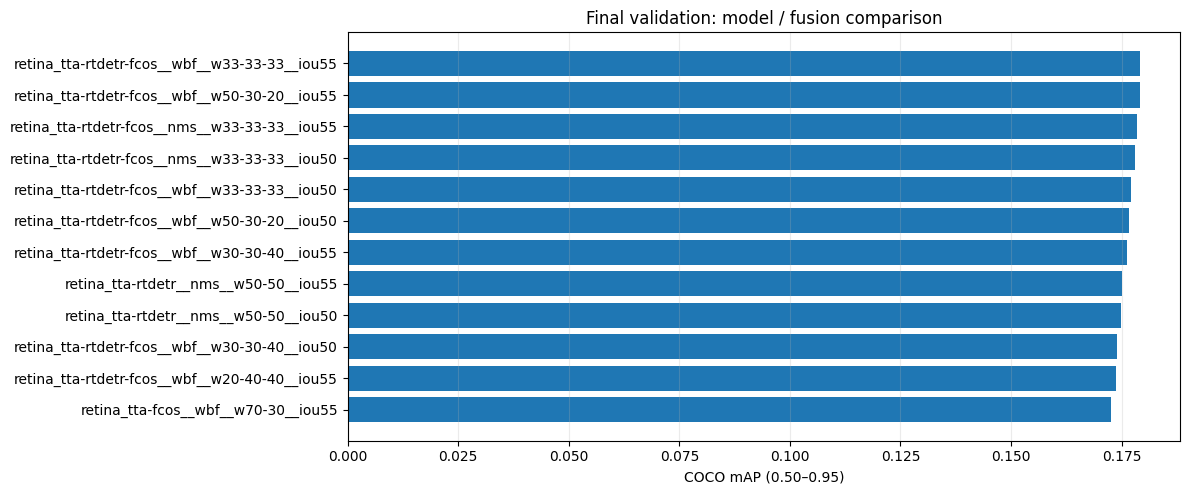

Best standalone: retina_tta mAP= 0.1617123008554799
Top result: retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55 mAP= 0.17926342230669653
Saved metrics and graph under /kaggle/working/final_ensemble_ablation


In [17]:
import matplotlib.pyplot as plt
plot_df=full_df.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,max(5,len(plot_df)*0.42)))
ax.barh(plot_df['candidate'],plot_df['mAP'])
ax.set_xlabel('COCO mAP (0.50–0.95)')
ax.set_title('Final validation: model / fusion comparison')
ax.grid(axis='x',alpha=0.25)
plt.tight_layout()
fig.savefig(OUT/'full_comparison_map.png',dpi=160,bbox_inches='tight')
plt.show()
print('Best standalone:',single_best,'mAP=',base_metrics[single_best]['mAP'])
print('Top result:',winner,'mAP=',full_df.iloc[0]['mAP'])
print('Saved metrics and graph under',OUT)

## 11. Test inference

In [18]:
RUN_TEST=True

In [ ]:
def load_test_records():
    if TEST_META_FILE is None:raise FileNotFoundError('No test_images.csv — add competition input.')
    df=pd.read_csv(TEST_META_FILE,dtype={'image_id':str})
    assert {'image_id','file_name','width','height'}.issubset(df.columns)
    assert df['image_id'].is_unique
    result=[]
    for r in df.to_dict('records'):
        result.append({'image_id':str(r['image_id']), 'file_name':str(r['file_name']),
                       'width':int(r['width']),'height':int(r['height'])})
    return result

def get_candidate_predictions(candidate,records,groups):
    if candidate in groups:
        return [x for per_image in groups[candidate].values() for x in per_image]
    return fuse_records(records,SPECS[candidate],groups,progress=True)

def create_submission(preds,records,dest):
    by_id=group_preds(preds)
    rows=[]
    for r in records:
        iid=str(r['image_id']);w=float(r['width']);h=float(r['height'])
        chunks=[]
        for q in sorted(by_id.get(iid,[]),key=lambda x:x['score'],reverse=True)[:OUTPUT_MAX_DET]:
            cid=int(q['category_id'])-1
            x,y,bw,bh=map(float,q['bbox']);x=max(0.,min(x,w));y=max(0.,min(y,h))
            bw=max(0.,min(bw,w-x));bh=max(0.,min(bh,h-y))
            conf=float(q['score'])
            if bw<=0 or bh<=0:continue
            assert 0<=cid<=7 and 0<=conf<=1
            chunks.append(f'{cid} {conf:.6f} {x:.2f} {y:.2f} {bw:.2f} {bh:.2f}')
        rows.append({'image_id':iid,'PredictionString':' '.join(chunks)})
    df=pd.DataFrame(rows,columns=['image_id','PredictionString'])
    assert len(df)==len(records) and df.image_id.is_unique
    assert all(len(s.split())%6==0 for s in df.PredictionString)
    df.to_csv(dest,index=False)
    print('Saved',dest,'rows=',len(df),'nonempty=',(df.PredictionString!='').sum())
    return df

if RUN_TEST:
    test_records=load_test_records()
    print('Test images:',len(test_records))
    top_candidates=full_df.head(TEST_TOP_N)['candidate'].tolist()
    required=set()
    for cand in top_candidates:
        required |= {cand} if cand in MODEL_NAMES else set(SPECS[cand]['models'])
    ck_kind={'fcos':'fcos_weights','retina_tta':'retina_weights','rtdetr':'rt_weights'}
    for model in required:
        if ASSETS[ck_kind[model]] is None:
            raise FileNotFoundError(f'Cannot run test: missing {model} checkpoint ({ck_kind[model]})')
    test_preds={}
    for model in sorted(required):
        path=OUT/f'test_{model}.json.gz'
        if path.exists():
            test_preds[model]=normalize_preds(read_json(path),'test')
        else:
            test_preds[model]=INFER_FNS[model](test_records,'test')
            write_gz(path,test_preds[model])
    test_groups={k:group_preds(v) for k,v in test_preds.items()}
    for rank,cand in enumerate(top_candidates,1):
        preds=get_candidate_predictions(cand,test_records,test_groups)
        write_gz(OUT/f'test_candidate_{rank}.json.gz',preds)
        create_submission(preds,test_records,OUT/f'submission_candidate_{rank}.csv')
    shutil.copy2(OUT/'submission_candidate_1.csv',WORK/'submission.csv')
    shutil.copy2(OUT/'submission_candidate_2.csv',WORK/'submission_candidate_2.csv')
    print('Submit:',WORK/'submission.csv','(best full validation candidate)')
else:
    print('RUN_TEST=False: all validation comparisons saved. Turn it on only after reviewing winner.')

Test images: 3811
Using fcos_weights : /kaggle/input/datasets/nastyadovbenchuk/fcos-result/model_weights.pth


FCOS test:   0%|          | 0/3811 [00:00<?, ?it/s]

Using retina_weights : /kaggle/input/datasets/nastyadovbenchuk/retinanet-results/retinanet_full_s3_e10_cosine_lr5e-5/best_model.pt


RetinaNet TTA test:   0%|          | 0/3811 [00:00<?, ?it/s]

Using rt_weights : /kaggle/input/datasets/nastyadovbenchuk/rt-detr/best.pt


RT-DETR test:   0%|          | 0/1906 [00:00<?, ?it/s]

retina_tta-rtdetr-fcos__wbf__w33-33-33__iou55:   0%|          | 0/3811 [00:00<?, ?it/s]

Saved /kaggle/working/final_ensemble_ablation/submission_candidate_1.csv rows= 3811 nonempty= 3811


retina_tta-rtdetr-fcos__wbf__w50-30-20__iou55:   0%|          | 0/3811 [00:00<?, ?it/s]

Saved /kaggle/working/final_ensemble_ablation/submission_candidate_2.csv rows= 3811 nonempty= 3811
Submit: /kaggle/working/submission.csv (best full validation candidate)
